# ETS Physics Module - V0 Validation

Validate the chilled-water-side physics exported by EnergyPlus before introducing Gymnasium or reinforcement learning.

Checks:
1. Delta-T = T_return - T_supply
2. Q_water = m_dot * Cp * Delta-T
3. Compare Q_water against EnergyPlus Cooling Coil Total Cooling Rate
4. Flag low-Delta-T operation relative to the current IDF design Delta-T
5. Preserve pump-flow and pump-power variables for later control work

This notebook is the interactive version of `ets_model_v0.py`, with added plots to visualize the ETS physics validation.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (14, 5)

CP_WATER = 4180.0  # J/(kg.K)

INPUT_CSV = Path("/Users/asperera/EnergyPlus/RL_UAE_HVAC_SOFTWARE/eplusout.csv")
DESIGN_DELTA_T = 4.0
FLOW_EPSILON = 1e-6
COOLING_EPSILON_W = 10.0

assert INPUT_CSV.exists(), f"File not found: {INPUT_CSV}"
INPUT_CSV

PosixPath('/Users/asperera/EnergyPlus/RL_UAE_HVAC_SOFTWARE/eplusout.csv')

## Column Definitions

EnergyPlus column names required for the water-side energy balance.

In [2]:
COL_Q_COIL = (
    "MAIN ZONE FCU COOLING COIL:Cooling Coil Total Cooling Rate [W](TimeStep)"
)
COL_T_SUPPLY = (
    "MAIN ZONE FCU COOLING COIL WATER INLET:System Node Temperature [C](TimeStep)"
)
COL_T_RETURN = (
    "MAIN ZONE FCU COOLING COIL WATER OUTLET:System Node Temperature [C](TimeStep)"
)
COL_COIL_FLOW = (
    "MAIN ZONE FCU COOLING COIL WATER INLET:System Node Mass Flow Rate [kg/s](TimeStep)"
)
COL_PUMP_FLOW = "CHW CIRC PUMP:Pump Mass Flow Rate [kg/s](TimeStep)"
COL_PUMP_POWER = "CHW CIRC PUMP:Pump Electricity Rate [W](TimeStep)"
COL_PLANT_SUPPLY = "CHW SUPPLY OUTLET NODE:System Node Temperature [C](TimeStep)"
COL_PLANT_RETURN = "CHW DEMAND OUTLET NODE:System Node Temperature [C](TimeStep)"
COL_ZONE_TEMP = "MAIN ZONE:Zone Mean Air Temperature [C](TimeStep)"
COL_ZONE_SETPOINT = (
    "MAIN ZONE:Zone Thermostat Cooling Setpoint Temperature [C](TimeStep)"
)

REQUIRED_COLUMNS = [
    "Date/Time",
    COL_Q_COIL,
    COL_T_SUPPLY,
    COL_T_RETURN,
    COL_COIL_FLOW,
    COL_PUMP_FLOW,
    COL_PUMP_POWER,
    COL_PLANT_SUPPLY,
    COL_PLANT_RETURN,
    COL_ZONE_TEMP,
    COL_ZONE_SETPOINT,
]


def validate_columns(df: pd.DataFrame) -> None:
    missing = [c for c in REQUIRED_COLUMNS if c not in df.columns]
    if missing:
        raise ValueError(
            "Required EnergyPlus columns are missing:\n  - "
            + "\n  - ".join(missing)
        )

## Build the ETS V0 Dataset

Compute Delta-T, water-side heat transfer, energy-balance error, and low-Delta-T flags.

In [3]:
def build_ets_v0(
    input_csv: Path,
    design_delta_t: float = 4.0,
    flow_epsilon: float = 1e-6,
    cooling_epsilon_w: float = 10.0,
):
    df = pd.read_csv(input_csv)
    validate_columns(df)

    out = pd.DataFrame()
    out["Date/Time"] = df["Date/Time"]

    # Raw EnergyPlus states
    out["q_coil_w"] = df[COL_Q_COIL]
    out["chw_supply_temp_c"] = df[COL_T_SUPPLY]
    out["chw_return_temp_c"] = df[COL_T_RETURN]
    out["coil_flow_kg_s"] = df[COL_COIL_FLOW]
    out["pump_flow_kg_s"] = df[COL_PUMP_FLOW]
    out["pump_power_w"] = df[COL_PUMP_POWER]
    out["plant_supply_temp_c"] = df[COL_PLANT_SUPPLY]
    out["plant_return_temp_c"] = df[COL_PLANT_RETURN]
    out["zone_temp_c"] = df[COL_ZONE_TEMP]
    out["zone_cooling_setpoint_c"] = df[COL_ZONE_SETPOINT]

    # ETS physics
    out["delta_t_c"] = (
        out["chw_return_temp_c"] - out["chw_supply_temp_c"]
    )

    out["q_water_w"] = (
        out["coil_flow_kg_s"] * CP_WATER * out["delta_t_c"]
    )

    out["q_balance_abs_error_w"] = (
        out["q_water_w"] - out["q_coil_w"]
    ).abs()

    out["q_balance_rel_error_pct"] = np.where(
        out["q_coil_w"].abs() > cooling_epsilon_w,
        100.0
        * out["q_balance_abs_error_w"]
        / out["q_coil_w"].abs(),
        np.nan,
    )

    # Active cooling: do not classify off-cycle/no-flow periods as low-Delta-T
    out["active_cooling"] = (
        (out["coil_flow_kg_s"] > flow_epsilon)
        & (out["q_coil_w"] > cooling_epsilon_w)
    )

    out["low_delta_t"] = (
        out["active_cooling"] & (out["delta_t_c"] < design_delta_t)
    )

    # Smooth severity for later RL reward design
    out["low_delta_t_severity"] = np.where(
        out["active_cooling"],
        np.maximum(
            0.0, (design_delta_t - out["delta_t_c"]) / design_delta_t
        ),
        0.0,
    )

    # Helpful engineering diagnostics
    out["pump_minus_coil_flow_kg_s"] = (
        out["pump_flow_kg_s"] - out["coil_flow_kg_s"]
    )

    out["zone_temp_error_c"] = (
        out["zone_temp_c"] - out["zone_cooling_setpoint_c"]
    )

    active = out[out["active_cooling"]].copy()

    summary = {
        "input_rows": len(out),
        "active_cooling_rows": len(active),
        "design_delta_t_c": design_delta_t,
        "mean_q_coil_kw": active["q_coil_w"].mean() / 1000.0,
        "max_q_coil_kw": active["q_coil_w"].max() / 1000.0,
        "mean_delta_t_c": active["delta_t_c"].mean(),
        "median_delta_t_c": active["delta_t_c"].median(),
        "min_delta_t_c": active["delta_t_c"].min(),
        "max_delta_t_c": active["delta_t_c"].max(),
        "mean_coil_flow_kg_s": active["coil_flow_kg_s"].mean(),
        "max_coil_flow_kg_s": active["coil_flow_kg_s"].max(),
        "mean_pump_power_w": active["pump_power_w"].mean(),
        "max_pump_power_w": active["pump_power_w"].max(),
        "water_side_q_mae_w": active["q_balance_abs_error_w"].mean(),
        "median_water_side_q_error_pct": active[
            "q_balance_rel_error_pct"
        ].median(),
        "mean_water_side_q_error_pct": active[
            "q_balance_rel_error_pct"
        ].mean(),
        "q_water_vs_q_coil_correlation": active[
            ["q_coil_w", "q_water_w"]
        ].corr().iloc[0, 1],
        "low_delta_t_fraction_pct": 100.0 * active["low_delta_t"].mean(),
    }

    return out, summary


out, summary = build_ets_v0(
    INPUT_CSV,
    design_delta_t=DESIGN_DELTA_T,
    flow_epsilon=FLOW_EPSILON,
    cooling_epsilon_w=COOLING_EPSILON_W,
)
out.head()

,Date/Time,q_coil_w,chw_supply_temp_c,chw_return_temp_c,coil_flow_kg_s,pump_flow_kg_s,pump_power_w,plant_supply_temp_c,plant_return_temp_c,zone_temp_c,zone_cooling_setpoint_c,delta_t_c,q_water_w,q_balance_abs_error_w,q_balance_rel_error_pct,active_cooling,low_delta_t,low_delta_t_severity,pump_minus_coil_flow_kg_s,zone_temp_error_c
0,01/21 00:15:00,0.0,7.0,7.0,0.0,0.0,0.0,7.0,7.0,20.0,24.0,0.0,0.0,0.0,NaN,False,False,0.0,0.0,-4.0
1,01/21 00:30:00,0.0,7.0,7.0,0.0,0.0,0.0,7.0,7.0,20.0,24.0,0.0,0.0,0.0,NaN,False,False,0.0,0.0,-4.0
2,01/21 00:45:00,0.0,7.0,7.0,0.0,0.0,0.0,7.0,7.0,20.0,24.0,0.0,0.0,0.0,NaN,False,False,0.0,0.0,-4.0
3,01/21 01:00:00,0.0,7.0,7.0,0.0,0.0,0.0,7.0,7.0,20.0,24.0,0.0,0.0,0.0,NaN,False,False,0.0,0.0,-4.0
4,01/21 01:15:00,0.0,7.0,7.0,0.0,0.0,0.0,7.0,7.0,20.0,24.0,0.0,0.0,0.0,NaN,False,False,0.0,0.0,-4.0


## Validation Summary

In [4]:
print("ETS Physics Module V0 - Summary\n" + "=" * 34)
for key, value in summary.items():
    if isinstance(value, float):
        print(f"{key:38s}: {value:.4f}")
    else:
        print(f"{key:38s}: {value}")

ETS Physics Module V0 - Summary
input_rows                            : 35232
active_cooling_rows                   : 32023
design_delta_t_c                      : 4.0000
mean_q_coil_kw                        : 5.5349
max_q_coil_kw                         : 14.0084
mean_delta_t_c                        : 1.9652
median_delta_t_c                      : 1.7664
min_delta_t_c                         : 0.1094
max_delta_t_c                         : 4.0002
mean_coil_flow_kg_s                   : 0.6115
max_coil_flow_kg_s                    : 0.9077
mean_pump_power_w                     : 156.2837
max_pump_power_w                      : 231.9299
water_side_q_mae_w                    : 23.8110
median_water_side_q_error_pct         : 0.3623
mean_water_side_q_error_pct           : 0.4245
q_water_vs_q_coil_correlation         : 0.9999
low_delta_t_fraction_pct              : 99.9969


## Q_water vs Q_coil Energy Balance

Compares the water-side computed cooling rate against EnergyPlus's reported coil cooling rate — they should track closely if the physics is consistent.

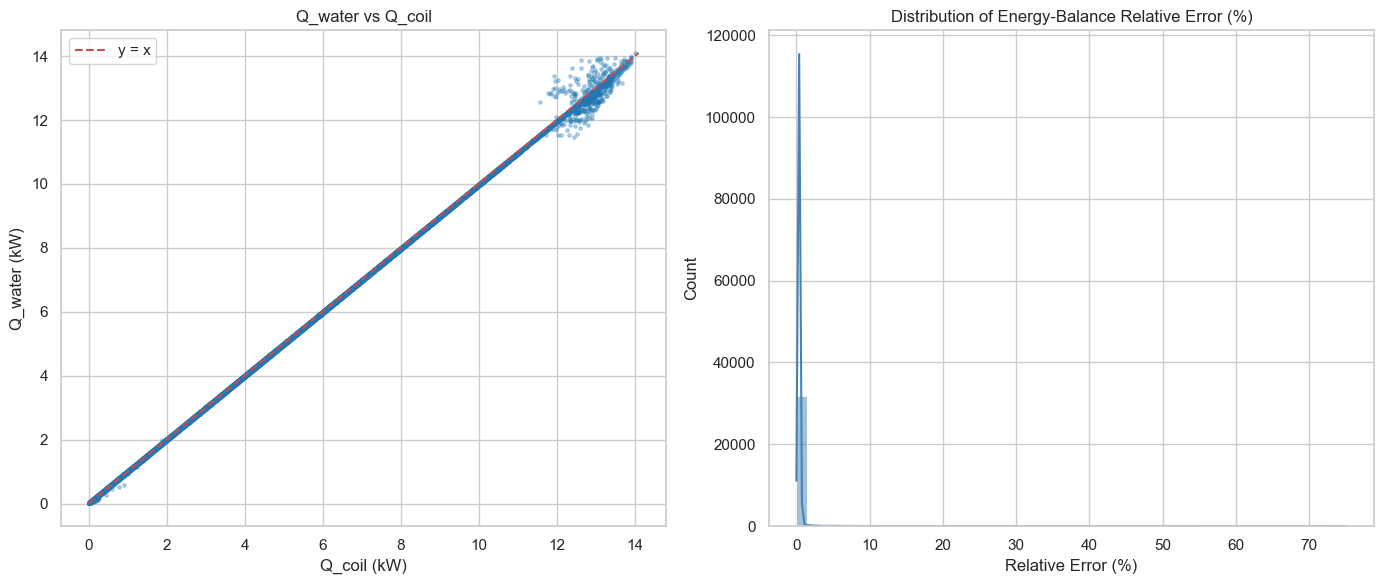

In [5]:
active = out[out["active_cooling"]].copy()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].scatter(active["q_coil_w"] / 1000.0, active["q_water_w"] / 1000.0, s=6, alpha=0.3, color="tab:blue")
lims = [0, max(active["q_coil_w"].max(), active["q_water_w"].max()) / 1000.0]
axes[0].plot(lims, lims, "r--", label="y = x")
axes[0].set_xlabel("Q_coil (kW)")
axes[0].set_ylabel("Q_water (kW)")
axes[0].set_title("Q_water vs Q_coil")
axes[0].legend()

sns.histplot(active["q_balance_rel_error_pct"].dropna(), bins=50, kde=True, ax=axes[1], color="steelblue")
axes[1].set_title("Distribution of Energy-Balance Relative Error (%)")
axes[1].set_xlabel("Relative Error (%)")

plt.tight_layout()
plt.show()

## Delta-T Analysis

Distribution and time series of chilled-water Delta-T, flagging low-Delta-T operation relative to the design value.

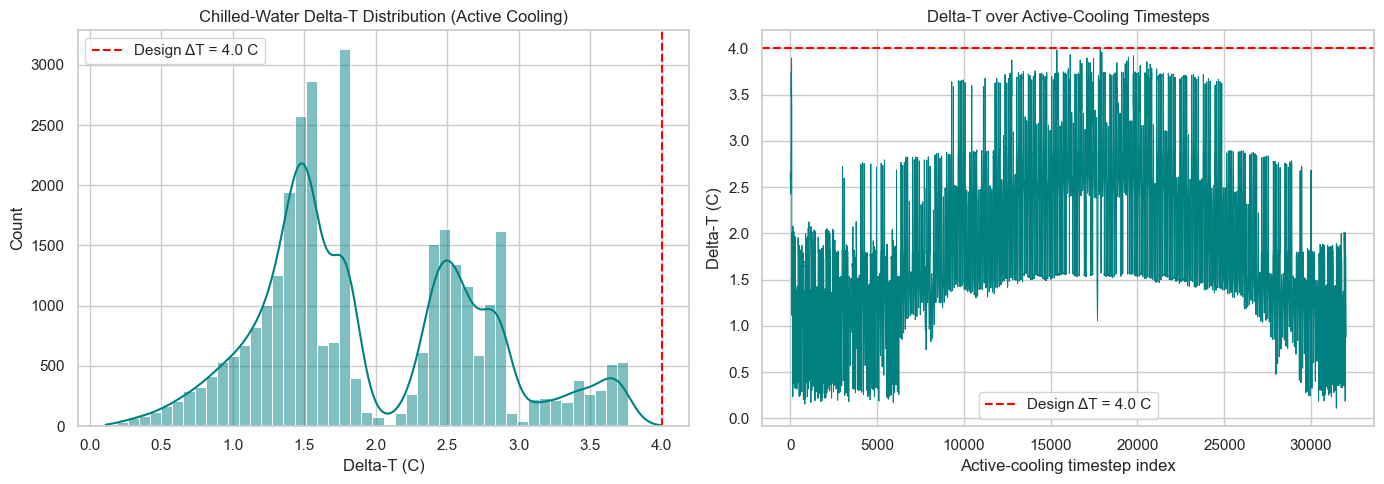

Low-Delta-T fraction: 100.00% of active-cooling timesteps


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(active["delta_t_c"], bins=50, kde=True, ax=axes[0], color="teal")
axes[0].axvline(DESIGN_DELTA_T, color="red", linestyle="--", label=f"Design ΔT = {DESIGN_DELTA_T} C")
axes[0].set_title("Chilled-Water Delta-T Distribution (Active Cooling)")
axes[0].set_xlabel("Delta-T (C)")
axes[0].legend()

axes[1].plot(range(len(active)), active["delta_t_c"].values, color="teal", linewidth=0.7)
axes[1].axhline(DESIGN_DELTA_T, color="red", linestyle="--", label=f"Design ΔT = {DESIGN_DELTA_T} C")
axes[1].set_title("Delta-T over Active-Cooling Timesteps")
axes[1].set_xlabel("Active-cooling timestep index")
axes[1].set_ylabel("Delta-T (C)")
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"Low-Delta-T fraction: {summary['low_delta_t_fraction_pct']:.2f}% of active-cooling timesteps")

## Pump Flow, Coil Flow, and Zone Temperature Error

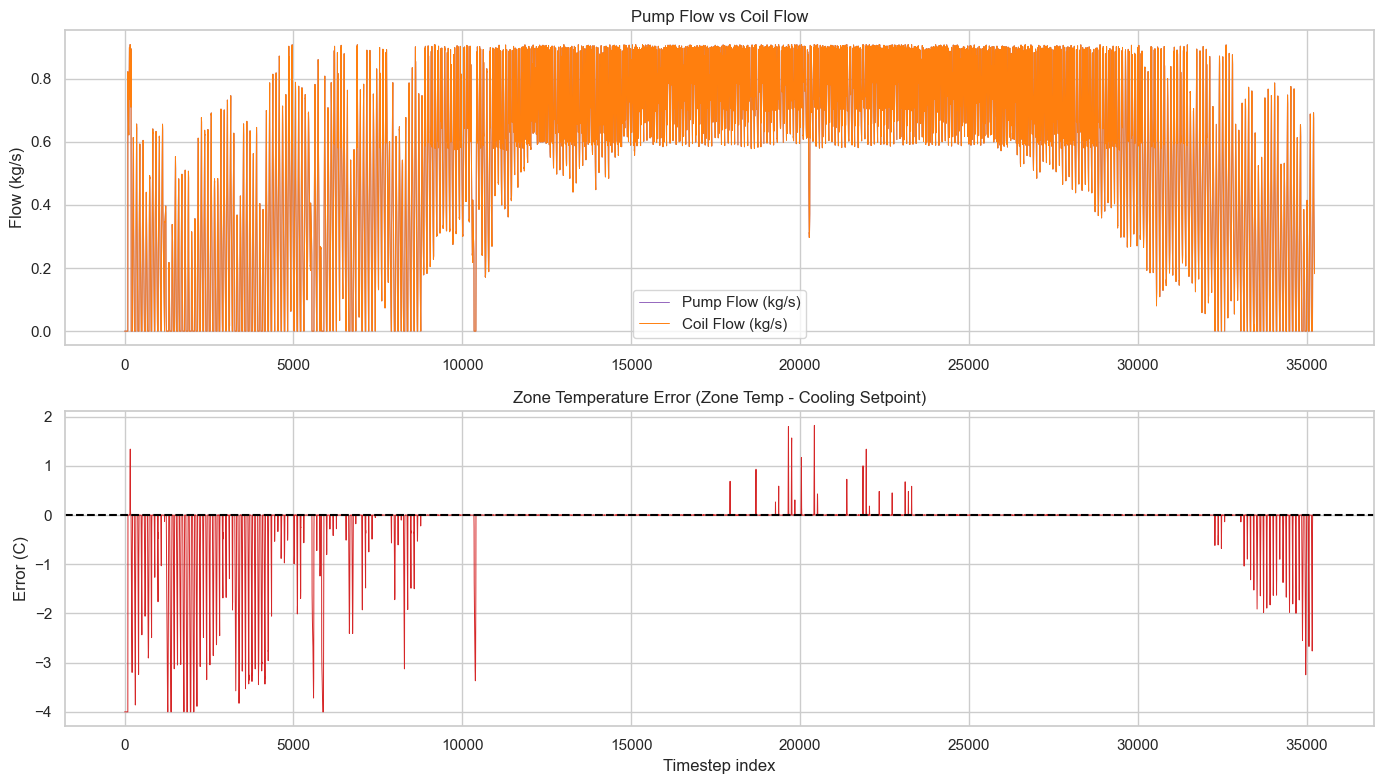

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=False)

axes[0].plot(range(len(out)), out["pump_flow_kg_s"], label="Pump Flow (kg/s)", color="tab:purple", linewidth=0.7)
axes[0].plot(range(len(out)), out["coil_flow_kg_s"], label="Coil Flow (kg/s)", color="tab:orange", linewidth=0.7)
axes[0].set_title("Pump Flow vs Coil Flow")
axes[0].set_ylabel("Flow (kg/s)")
axes[0].legend()

axes[1].plot(range(len(out)), out["zone_temp_error_c"], color="tab:red", linewidth=0.7)
axes[1].axhline(0.0, color="black", linestyle="--")
axes[1].set_title("Zone Temperature Error (Zone Temp - Cooling Setpoint)")
axes[1].set_ylabel("Error (C)")
axes[1].set_xlabel("Timestep index")

plt.tight_layout()
plt.show()

## Save Validated Dataset & Summary Report

In [ ]:
output_csv = INPUT_CSV.with_name("ets_v0_validated.csv")
summary_txt = INPUT_CSV.with_name("ets_v0_summary.txt")

out.to_csv(output_csv, index=False)

with open(summary_txt, "w", encoding="utf-8") as f:
    f.write("ETS Physics Module V0 - Validation Summary\n")
    f.write("=" * 44 + "\n")
    for key, value in summary.items():
        if isinstance(value, float):
            f.write(f"{key}: {value:.6f}\n")
        else:
            f.write(f"{key}: {value}\n")

print(f"Validated timestep dataset: {output_csv}")
print(f"Summary report:             {summary_txt}")